In [1]:
import os
import sys
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, mean, expr, stddev, round, when, count, sum as spark_sum, floor, datediff, to_date, lit
from pyspark.sql.window import Window
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

os.environ['PYSPARK_PYTHON'] = sys.executable
os.environ['PYSPARK_DRIVER_PYTHON'] = sys.executable

print("Iniciando o Spark...")
spark = SparkSession.builder \
    .appName("Leitura_CadUnico") \
    .config("spark.driver.memory", "8g") \
    .getOrCreate()

print("Spark iniciado com sucesso!")

print("Lendo o arquivo...")
df = spark.read.csv("PESSOA_2018.TXT", header=True, sep=";", inferSchema=True)

Iniciando o Spark...
Spark iniciado com sucesso!
Lendo o arquivo...


In [2]:
df = df.withColumn("Idade", floor(datediff(to_date(lit("2018-12-31")), to_date(col("DT_NASC_PESSOA"), "yyyy-MM-dd")) / 365.25))

# Faixas Etárias
df = df.withColumn("Faixa_Etaria",
    when(col("Idade") <= 17, "Crianças e Adolescentes")
    .when((col("Idade") >= 18) & (col("Idade") <= 29), "Jovens")
    .when((col("Idade") >= 30) & (col("Idade") <= 59), "Adultos")
    .otherwise("Idosos")
)

#Nível de Escolaridade 
df = df.withColumn("Escolaridade",
    when(col("CO_CURSO_FREQ_PESSOA_MEMB").isin([1, 2, 3, 4, 10, 15]), "Sem Instrucao/Fundamental Incomp.")
    .when(col("CO_CURSO_FREQ_PESSOA_MEMB").isin([5, 6, 11]), "Fundamental Completo")
    .when(col("CO_CURSO_FREQ_PESSOA_MEMB").isin([7, 8, 9, 12]), "Medio")
    .when(col("CO_CURSO_FREQ_PESSOA_MEMB") == 13, "Superior")
    .otherwise("Nao Informado")
)

# Substitui nulos por 0 na renda de emprego
df = df.withColumn("Renda_Ind", when(col("VL_REMUNER_EMPREGO_MEMB").isNull(), 0).otherwise(col("VL_REMUNER_EMPREGO_MEMB")))
df = df.withColumn("Trabalha", when(col("CO_TRABALHOU_SEMANA_MEMB") == 1, 1).otherwise(0))

# Renda Familiar Per Capita
window_familia = Window.partitionBy("CO_FAMILIAR_FAM")
df = df.withColumn("Renda_Total_Fam", spark_sum("Renda_Ind").over(window_familia))
df = df.withColumn("Qtd_Membros_Fam", count("*").over(window_familia))
df = df.withColumn("Renda_Per_Capita", col("Renda_Total_Fam") / col("Qtd_Membros_Fam"))
df = df.withColumn("Extrema_Pobreza", when(col("Renda_Per_Capita") <= 89, "Sim").otherwise("Nao"))

In [3]:
# ETAPA 1 E PERGUNTA 1: Demografia e Desigualdade

print("\n--- Etapa 1.1: Distribuição de Idade por Sexo e Cor/Raça ---")

idade_stats = df.groupBy("CO_SEXO_PESSOA", "CO_RACA_COR_PESSOA").agg(
    round(mean("Idade"), 2).alias("Media_Idade"),
    expr("percentile_approx(Idade, 0.5)").alias("Mediana_Idade"),
    round(stddev("Idade"), 2).alias("Desvio_Padrao_Idade")
)

idade_stats.orderBy("CO_SEXO_PESSOA", "CO_RACA_COR_PESSOA").show()

print("\n--- Pergunta 1: Desigualdade de Renda (Média e Mediana) por Sexo e Cor/Raça ---")
# Sexo: 1 (Masculino), 2 (Feminino) | Cor: 1 (Branca), 2 (Preta), 3 (Amarela), 4 (Parda), 5 (Indígena)

renda_stats = df.groupBy("CO_SEXO_PESSOA", "CO_RACA_COR_PESSOA").agg(
    round(mean("Renda_Ind"), 2).alias("Media_Renda"),
    expr("percentile_approx(Renda_Ind, 0.5)").alias("Mediana_Renda")
)

renda_stats.orderBy("CO_SEXO_PESSOA", "CO_RACA_COR_PESSOA").show()


--- Etapa 1.1: Distribuição de Idade por Sexo e Cor/Raça ---
+--------------+------------------+-----------+-------------+-------------------+
|CO_SEXO_PESSOA|CO_RACA_COR_PESSOA|Media_Idade|Mediana_Idade|Desvio_Padrao_Idade|
+--------------+------------------+-----------+-------------+-------------------+
|             1|              NULL|      55.51|           62|              18.68|
|             1|                 1|      27.59|           20|              22.13|
|             1|                 2|      31.71|           28|              21.02|
|             1|                 3|       27.2|           20|              21.96|
|             1|                 4|      25.58|           19|              20.05|
|             1|                 5|      20.88|           16|              17.03|
|             2|              NULL|      47.63|           46|              18.43|
|             2|                 1|      31.29|           29|              21.46|
|             2|                 2| 

In [4]:

# ETAPA 1.2, 1.3 E PERGUNTA 2: Trabalho e Escolaridade

print("\n--- Etapa 1.3: Renda Média por Nível de Escolaridade ---")

renda_escolaridade = df.groupBy("Escolaridade").agg(round(mean("Renda_Ind"), 2).alias("Renda_Media"))
renda_escolaridade.show()

print("\n--- Etapa 1.2 e Pergunta 2: Ocupação (Informal/Formal simulado*) por Escolaridade ---")

df_ativos = df.filter((col("Idade") >= 18) & (col("Idade") <= 65))
taxa_ocup_escolaridade = df_ativos.groupBy("Escolaridade").agg(
    count("*").alias("Total_Pessoas"),
    spark_sum("Trabalha").alias("Total_Trabalhando")
).withColumn("Taxa_Ocupacao_Perc", round((col("Total_Trabalhando") / col("Total_Pessoas")) * 100, 2))

taxa_ocup_escolaridade.show()


--- Etapa 1.3: Renda Média por Nível de Escolaridade ---
+--------------------+-----------+
|        Escolaridade|Renda_Media|
+--------------------+-----------+
|       Nao Informado|      16.13|
|Fundamental Completo|     198.83|
|Sem Instrucao/Fun...|     139.43|
|               Medio|     274.04|
|            Superior|     685.47|
+--------------------+-----------+


--- Etapa 1.2 e Pergunta 2: Ocupação (Informal/Formal simulado*) por Escolaridade ---
+--------------------+-------------+-----------------+------------------+
|        Escolaridade|Total_Pessoas|Total_Trabalhando|Taxa_Ocupacao_Perc|
+--------------------+-------------+-----------------+------------------+
|       Nao Informado|      6629796|          1303714|             19.66|
|Fundamental Completo|     10892565|          4626465|             42.47|
|Sem Instrucao/Fun...|      8673593|          3540710|             40.82|
|               Medio|     14157672|          5961348|             42.11|
|            Superior

In [5]:

# ETAPA 2 E PERGUNTA 3: Perfil, PCD e Vulnerabilidade

print("\n--- Etapa 2.1: Proporção com Trabalho Remunerado por Faixa Etária ---")

trabalho_faixa_etaria = df.groupBy("Faixa_Etaria").agg(
    count("*").alias("Total"),
    spark_sum("Trabalha").alias("Total_Trabalhando")
).withColumn("Proporcao_Trabalhando_Perc", round((col("Total_Trabalhando") / col("Total")) * 100, 2))

trabalho_faixa_etaria.show()

print("\n--- Etapa 2.2 e Pergunta 3: PCD (Pessoas com Deficiência) por Faixa Etária e Extrema Pobreza ---")

# CO_DEFICIENCIA_MEMB == 1 significa que a pessoa declarou ter deficiência
df_pcd = df.filter(col("CO_DEFICIENCIA_MEMB") == 1)
pcd_vulnerabilidade = df_pcd.groupBy("Faixa_Etaria", "Extrema_Pobreza").count()
pcd_vulnerabilidade.show()



--- Etapa 2.1: Proporção com Trabalho Remunerado por Faixa Etária ---
+--------------------+--------+-----------------+--------------------------+
|        Faixa_Etaria|   Total|Total_Trabalhando|Proporcao_Trabalhando_Perc|
+--------------------+--------+-----------------+--------------------------+
|              Idosos| 6945727|           753827|                     10.85|
|              Jovens|14329701|          3783756|                      26.4|
|             Adultos|24147550|         11452393|                     47.43|
|Crianças e Adoles...|28212068|            51295|                      0.18|
+--------------------+--------+-----------------+--------------------------+


--- Etapa 2.2 e Pergunta 3: PCD (Pessoas com Deficiência) por Faixa Etária e Extrema Pobreza ---
+--------------------+---------------+-------+
|        Faixa_Etaria|Extrema_Pobreza|  count|
+--------------------+---------------+-------+
|             Adultos|            Sim|1224128|
|             Adultos|    

In [6]:
# PERGUNTA 4: Impacto de Crianças na Ocupação das Mães

print("\n--- Pergunta 4: Taxa de Ocupação de Mães com Crianças de 0 a 6 anos ---")
familias_com_criancas = df.filter(col("Idade") <= 6).select("CO_FAMILIAR_FAM").distinct().withColumn("Tem_Crianca_0_6", lit("Sim"))

# Mulheres (Sexo=2) que são Responsáveis Familiares (Parentesco=1)
maes = df.filter((col("CO_SEXO_PESSOA") == 2) & (col("CO_PARENTESCO_RF_PESSOA") == 1))
maes = maes.join(familias_com_criancas, on="CO_FAMILIAR_FAM", how="left").fillna({"Tem_Crianca_0_6": "Nao"})

taxa_ocupacao_maes = maes.groupBy("Tem_Crianca_0_6").agg(
    count("*").alias("Total_Maes"),
    spark_sum("Trabalha").alias("Total_Trabalham")
).withColumn("Taxa_Ocupacao_Perc", round((col("Total_Trabalham") / col("Total_Maes")) * 100, 2))
taxa_ocupacao_maes.show()



--- Pergunta 4: Taxa de Ocupação de Mães com Crianças de 0 a 6 anos ---
+---------------+----------+---------------+------------------+
|Tem_Crianca_0_6|Total_Maes|Total_Trabalham|Taxa_Ocupacao_Perc|
+---------------+----------+---------------+------------------+
|            Sim|   7667531|        2834165|             36.96|
|            Nao|  14636854|        5115716|             34.95|
+---------------+----------+---------------+------------------+



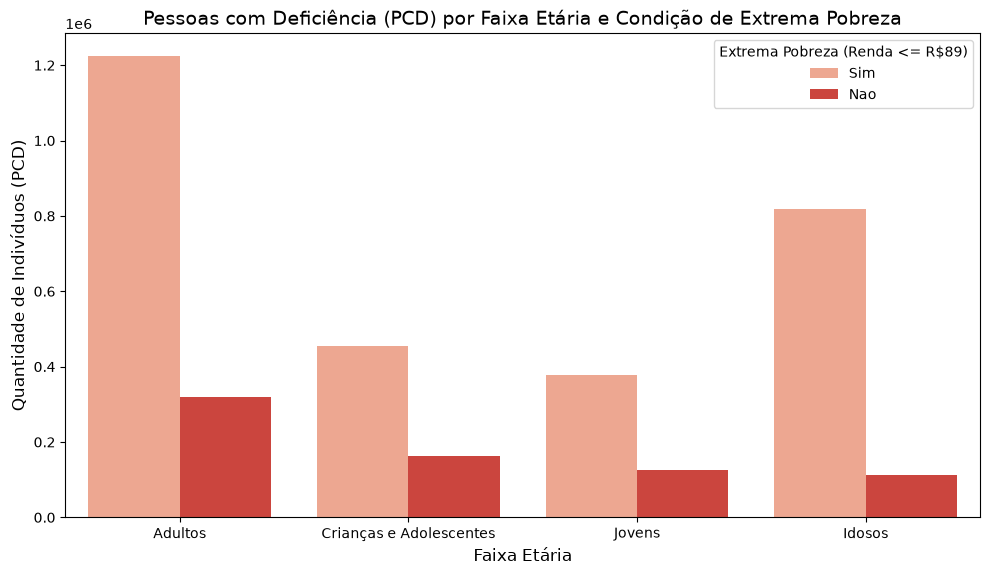

C:\Users\Matheus\AppData\Local\Temp\ipykernel_14348\213463743.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=pdf_trab_idade, x='Faixa_Etaria', y='Proporcao_Trabalhando_Perc', palette='Blues_r')


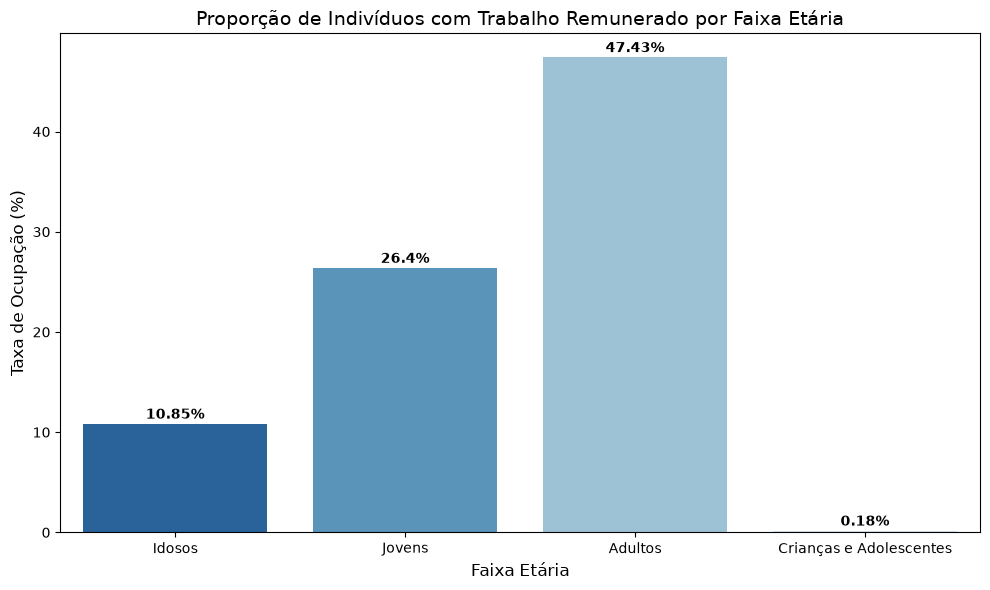

In [7]:
# ETAPA 4: Visualização Gráfica
pdf_pcd = pcd_vulnerabilidade.toPandas()
pdf_trab_idade = trabalho_faixa_etaria.toPandas()

# Gráfico 1: Pessoas com Deficiência e Extrema Pobreza
plt.figure(figsize=(10, 6))
sns.barplot(data=pdf_pcd, x='Faixa_Etaria', y='count', hue='Extrema_Pobreza', palette='Reds')
plt.title('Pessoas com Deficiência (PCD) por Faixa Etária e Condição de Extrema Pobreza', fontsize=14)
plt.xlabel('Faixa Etária', fontsize=12)
plt.ylabel('Quantidade de Indivíduos (PCD)', fontsize=12)
plt.legend(title='Extrema Pobreza (Renda <= R$89)')
plt.tight_layout()
plt.show()

# Gráfico 2: Proporção de Trabalho Remunerado por Faixa Etária
plt.figure(figsize=(10, 6))
sns.barplot(data=pdf_trab_idade, x='Faixa_Etaria', y='Proporcao_Trabalhando_Perc', palette='Blues_r')
plt.title('Proporção de Indivíduos com Trabalho Remunerado por Faixa Etária', fontsize=14)
plt.xlabel('Faixa Etária', fontsize=12)
plt.ylabel('Taxa de Ocupação (%)', fontsize=12)
for i, v in enumerate(pdf_trab_idade['Proporcao_Trabalhando_Perc']):
    plt.text(i, v + 0.5, f"{v}%", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()